**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: ARAH ROJAS BLANCO
*   MATRÍCULA: A00834299

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [146]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [147]:
cardio_df = pd.read_csv("heart_disease.csv", index_col="id")
cardio_df.info()
display(cardio_df.nunique().to_frame("Valores únicos"))

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


,Valores únicos
age,50
sex,2
origin,4
cp,4
trestbps,60
chol,216
fbs,2
restecg,3
thalch,119
exang,2


 Se cargaron 918 registros y 15 columnas, con id como índice único. Hay 7 columnas numéricas y 8 no numéricas: 6 contienen texto y 2 contienen valores booleanos con faltantes. Los identificadores llegan hasta 920, pero no son consecutivos: esto no significa que existan 920 filas. nunique() excluye los faltantes.

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [148]:
# Revisamos las columnas numéricas que tienen pocos valores diferentes.
numericas = cardio_df.select_dtypes(include="number")
print(numericas.nunique())

age          50
trestbps     60
chol        216
thalch      119
oldpeak      53
ca            4
num           5
dtype: int64


In [149]:
print("ca:", cardio_df["ca"].unique())
print("num:", cardio_df["num"].unique())

ca: [ 0.  3.  2.  1. nan]
num: [0 2 1 3 4]


In [150]:
cardio_df["num"] = pd.Categorical(cardio_df["num"], categories=[0, 1, 2, 3, 4], ordered=True)

ca tiene cuatro valores distintos y representa el número de vasos principales coloreados por fluoroscopía. Se conserva como numérica discreta porque es un conteo. num tiene cinco valores y representa el grado de enfermedad según la actividad; se convierte en categórica ordinal con el orden 0 < 1 < 2 < 3 < 4.

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [151]:
numericas = cardio_df.select_dtypes(include="number")
categoricas = cardio_df.select_dtypes(exclude="number")

estadisticas = numericas.describe()
estadisticas.loc["sesgo"] = numericas.skew()
estadisticas.loc["curtosis"] = numericas.kurt()
display(estadisticas)

display(categoricas.describe())
for columna in categoricas:
    print(columna)
    print(categoricas[columna].value_counts(dropna=False))

,age,trestbps,chol,thalch,oldpeak,ca
count,918.000000,859.000000,888.000000,863.000000,856.000000,309.000000
mean,53.530501,132.294529,242.189189,137.528389,0.880607,0.676375
std,9.412783,18.535875,53.424806,25.950226,1.091840,0.935653
min,28.000000,80.000000,85.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,216.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000
75%,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000
sesgo,-0.193710,0.630411,1.640672,-0.209319,1.037990,1.165978
curtosis,-0.382511,0.632992,6.573848,-0.483939,1.119834,0.199498


,sex,origin,cp,fbs,restecg,exang,slope,thal,num
count,918,918,918,829,918,863,610,434,918
unique,2,4,4,2,3,2,3,3,5
top,Male,Cleveland,asymptomatic,False,normal,False,flat,normal,0
freq,724,304,495,691,551,526,345,196,411


sex
sex
Male      724
Female    194
Name: count, dtype: int64
origin
origin
Cleveland        304
Hungary          292
VA Long Beach    200
Switzerland      122
Name: count, dtype: int64
cp
cp
asymptomatic       495
non-anginal        204
atypical angina    174
typical angina      45
Name: count, dtype: int64
fbs
fbs
False    691
True     138
NaN       89
Name: count, dtype: int64
restecg
restecg
normal              551
lv hypertrophy      188
st-t abnormality    179
Name: count, dtype: int64
exang
exang
False    526
True     337
NaN       55
Name: count, dtype: int64
slope
slope
flat           345
NaN            308
upsloping      202
downsloping     63
Name: count, dtype: int64
thal
thal
NaN                  484
normal               196
reversable defect    192
fixed defect          46
Name: count, dtype: int64
num
num
0    411
1    263
2    109
3    107
4     28
Name: count, dtype: int64


La edad media es 53.53 años y su mediana es 54. chol tiene sesgo positivo de 1.641 y oldpeak de 1.038: presentan colas hacia valores altos. trestbps tiene una asimetría positiva más moderada (0.630). age y thalch muestran sesgos negativos pequeños. La curtosis reportada es exceso de curtosis (la normal tiene valor 0), calculada con pandas.kurt().
Las estadísticas cuantitativas excluyen NaN, por lo que los tamaños de muestra varían entre columnas. Las tablas categóricas incluyen también la frecuencia de NaN.

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [152]:
porcentaje_faltantes = cardio_df.isna().mean() * 100
print(porcentaje_faltantes)

age          0.000000
sex          0.000000
origin       0.000000
cp           0.000000
trestbps     6.427015
chol         3.267974
fbs          9.694989
restecg      0.000000
thalch       5.991285
exang        5.991285
oldpeak      6.753813
slope       33.551198
ca          66.339869
thal        52.723312
num          0.000000
dtype: float64


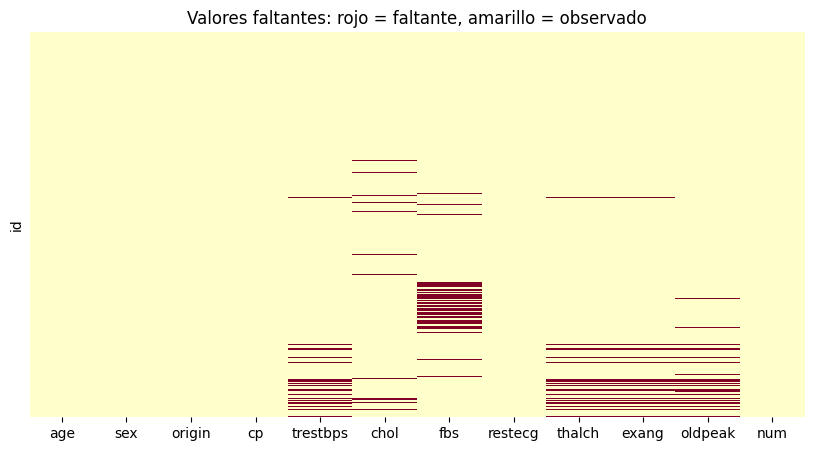

In [153]:
columnas_eliminar = porcentaje_faltantes[porcentaje_faltantes > 30].index
cardio_df = cardio_df.drop(columns=columnas_eliminar)

plt.figure(figsize=(10, 5))
sns.heatmap(cardio_df.isna(), yticklabels=False, cmap="YlOrRd", cbar=False)
plt.title("Valores faltantes: rojo = faltante, amarillo = observado")
plt.show()

In [154]:
# Pacientes sin thalch, antes de imputar
faltantes = cardio_df[cardio_df["thalch"].isna()]

print(len(faltantes))
print(faltantes[["exang", "trestbps", "oldpeak"]].isna().sum())

55
exang       55
trestbps    55
oldpeak     54
dtype: int64


In [155]:
print(cardio_df["thalch"].isna().equals(cardio_df["exang"].isna()))

True


Se eliminaron slope (33.55%), ca (66.34%) y thal (52.72%) porque superan el 30% de valores faltantes.
En el mapa de calor, varias líneas rojas coinciden en las mismas filas. Los conteos confirman que:
- A 55 pacientes les falta thalch. A esos mismos pacientes también les faltan exang y trestbps.
- En 54 de esos 55 pacientes también falta oldpeak.

Esta coincidencia tiene sentido clínico: thalch mide la frecuencia cardíaca máxima, exang indica dolor de pecho durante el ejercicio y oldpeak registra cambios eléctricos del corazón asociados al esfuerzo. Si la prueba de esfuerzo no se realizó o quedó incompleta, podrían faltar estos datos juntos. trestbps mide la presión en reposo y podría faltar por un registro incompleto de la misma evaluación.
La prueba de esfuerzo registra frecuencia cardíaca, presión arterial y actividad eléctrica, según la American Heart Association. Esta es una explicación posible; el archivo no permite confirmar la causa de los faltantes.
 Fuente: https://cpr.heart.org/-/media/files/health-topics/answers-by-heart/what-is-a-stress-test.pdf

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [156]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [157]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

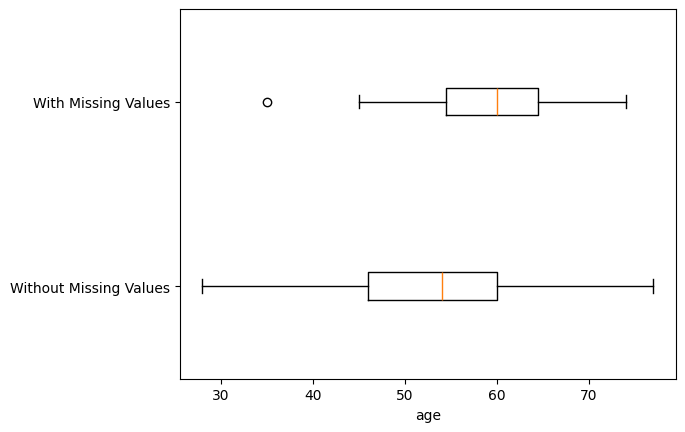

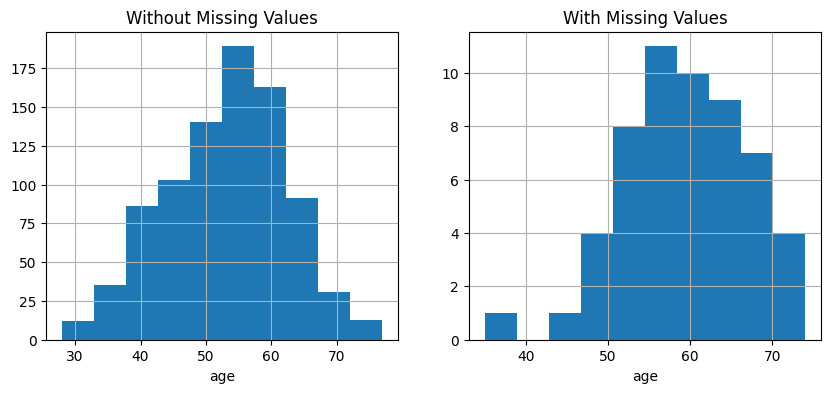

p-value of t-test: 1.5041244185890902e-06


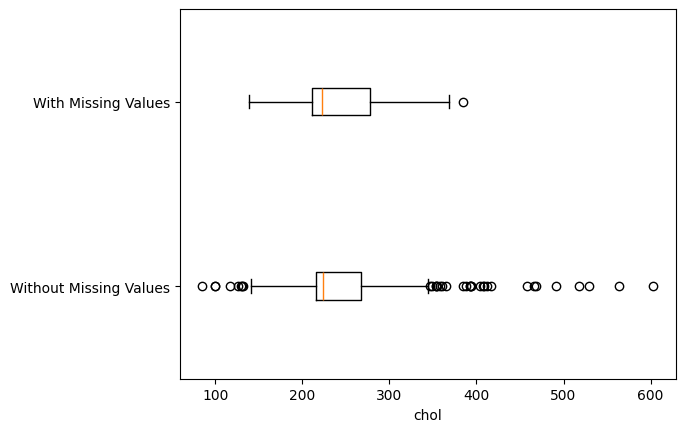

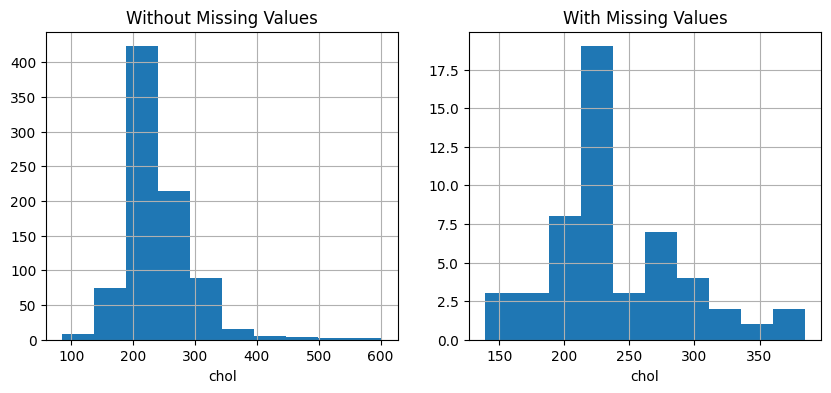

p-value of t-test: 0.7165289974295672


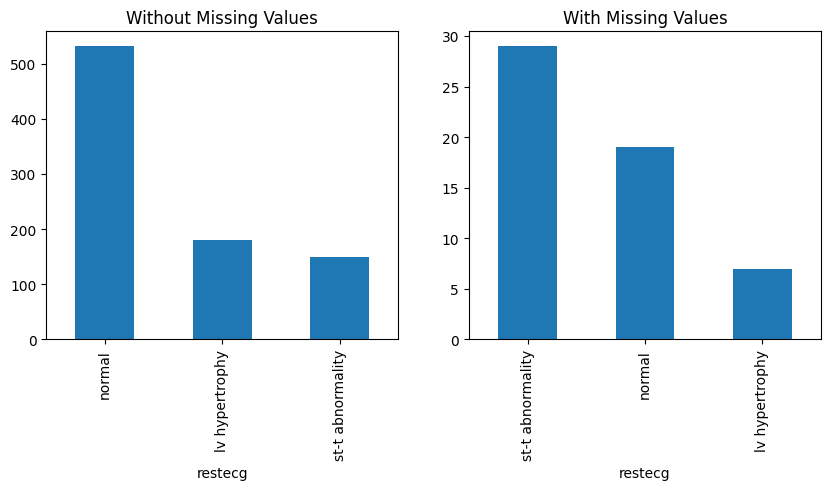

p-value of Chi_squared test: 1.1472889573985467e-09


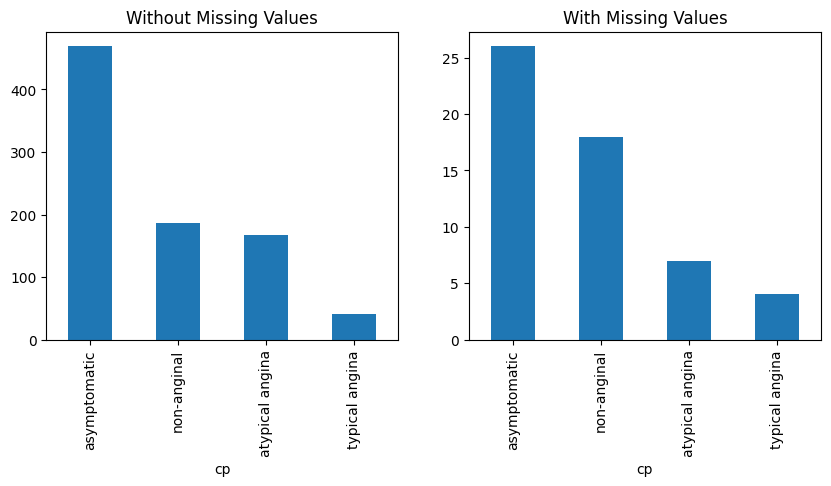

p-value of Chi_squared test: 0.15420097177251701


In [158]:
# Identificamos los pacientes sin datos en thalch.
faltantes = cardio_df["thalch"].isna()

# Aplicamos las funciones a las cuatro variables solicitadas.
Diagnose_MV_Numerical(cardio_df, "age", faltantes)
Diagnose_MV_Numerical(cardio_df, "chol", faltantes)

Diagnose_MV_Categorical(cardio_df, "restecg", faltantes)
Diagnose_MV_Categorical(cardio_df, "cp", faltantes)

Con un nivel de significancia de 0.05, se encontraron diferencias en edad (p ≈ 0.0000015) y restecg (p ≈ 0.0000000011). Los pacientes sin datos de thalch tienden a ser mayores y presentan una mayor proporción de anomalías ST-T. No se encontraron diferencias significativas para chol (p ≈ 0.717) ni cp (p ≈ 0.154).
Como la ausencia de thalch está relacionada con otras variables, hay evidencia contra MCAR, que significa que los datos faltan completamente al azar. MAR es una explicación razonable porque los faltantes se relacionan con información observada, aunque estas pruebas no permiten confirmar ese mecanismo.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

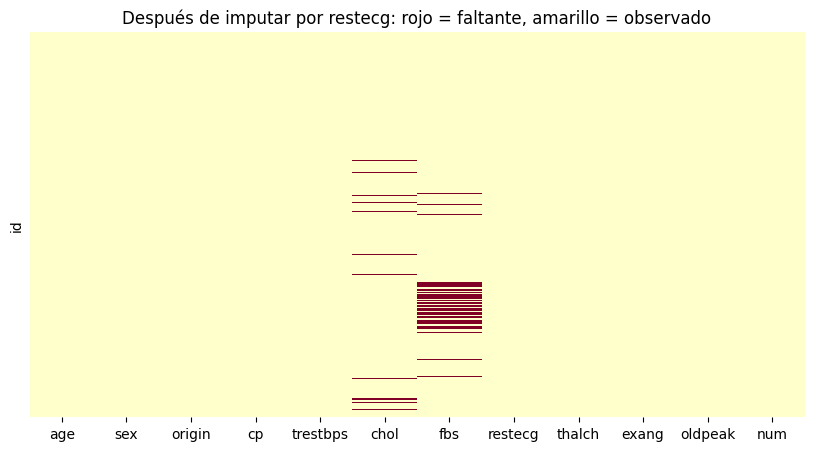

In [159]:
# Mediana de cada variable dentro de los grupos de restecg.
for columna in ["thalch", "oldpeak", "trestbps"]:
    medianas = cardio_df.groupby("restecg")[columna].transform("median")
    cardio_df[columna] = cardio_df[columna].fillna(medianas)

# Para exang usamos la moda porque es una variable categórica.
modas = cardio_df.groupby("restecg")["exang"].transform(lambda grupo: grupo.mode().iloc[0])
faltantes_exang = cardio_df["exang"].isna()
cardio_df.loc[faltantes_exang, "exang"] = modas[faltantes_exang]

plt.figure(figsize=(10, 5))
sns.heatmap(cardio_df.isna(), yticklabels=False, cmap="YlOrRd", cbar=False)
plt.title("Después de imputar por restecg: rojo = faltante, amarillo = observado")
plt.show()

Se agruparon los pacientes según restecg, que indica el resultado del electrocardiograma. Dentro de cada grupo, se rellenaron los faltantes de thalch, oldpeak y trestbps con la mediana, porque los valores extremos la afectan menos que a la media.

Para exang se usó la moda, es decir, la respuesta más frecuente del grupo, porque sus valores son verdadero o falso.

El mapa de calor muestra que estas cuatro variables ya no tienen faltantes. Solo quedan datos por completar en chol y fbs.

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [160]:
imputador_chol = SimpleImputer(strategy="median")
cardio_df[["chol"]] = imputador_chol.fit_transform(cardio_df[["chol"]])

imputador_fbs = SimpleImputer(strategy="most_frequent")
cardio_df[["fbs"]] = imputador_fbs.fit_transform(cardio_df[["fbs"]])

Justificación: Para chol se utilizó la mediana porque presenta valores extremos que pueden afectar la media. Para fbs se utilizó la moda, es decir, la respuesta más frecuente, porque sus valores son verdadero o falso. Ambas imputaciones se hicieron con SimpleImputer, utilizando los datos de toda la columna.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

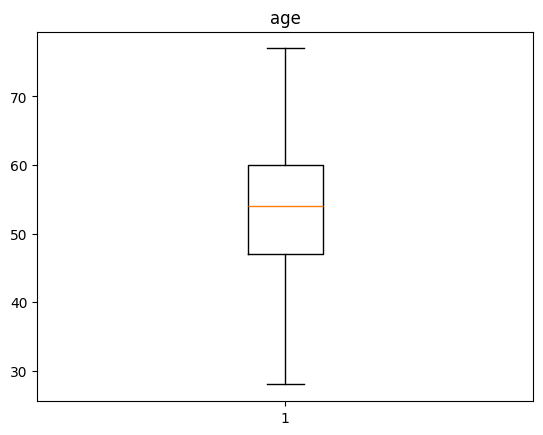

age valores atípicos: []


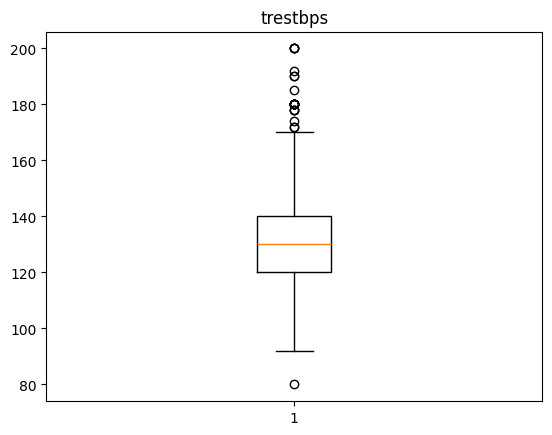

trestbps valores atípicos: [ 80. 172. 180. 200. 174. 178. 192. 180. 178. 180. 190. 180. 180. 180.
 180. 200. 180. 180. 180. 200. 185. 200. 180. 178. 172. 180. 190.]


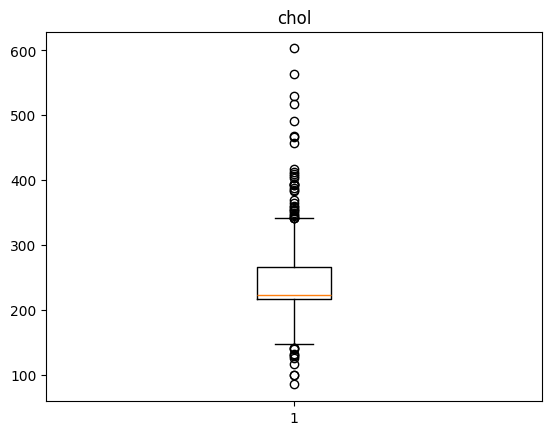

chol valores atípicos: [141. 126. 131. 132. 129. 100.  85. 117. 100. 142. 139. 354. 353. 417.
 360. 407. 564. 394. 409. 342. 358. 412. 468. 365. 344. 394. 347. 466.
 529. 392. 355. 603. 342. 404. 518. 388. 491. 342. 393. 458. 384. 349.
 369. 385.]


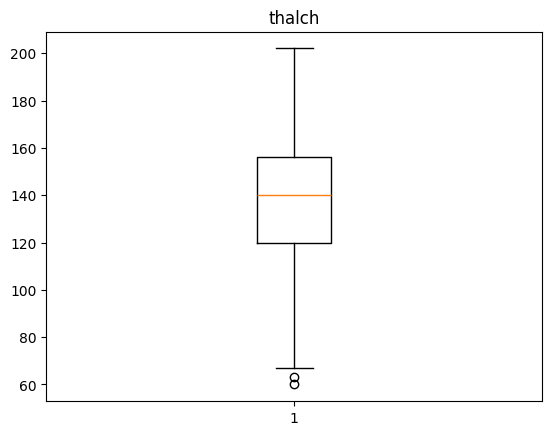

thalch valores atípicos: [60. 63.]


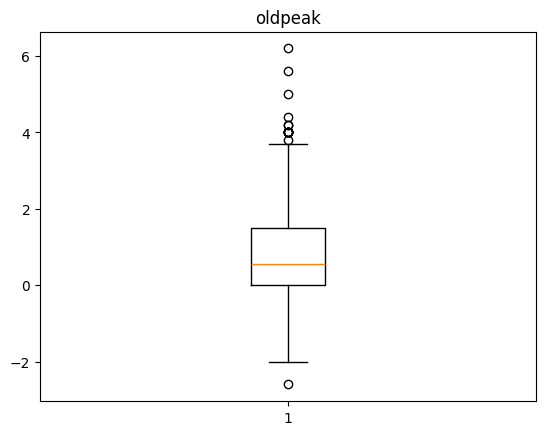

oldpeak valores atípicos: [-2.6  6.2  4.   5.6  4.   4.2  4.2  3.8  4.4  4.   4.   5.   4.   4.
  4.   4. ]


In [161]:
numericas = cardio_df.select_dtypes(include="number").columns
outliers_graficos = {}

for columna in numericas:
    plt.figure()
    resultado_boxplot = plt.boxplot(cardio_df[columna])
    plt.title(columna)
    plt.show()

    outliers_graficos[columna] = resultado_boxplot["fliers"][0].get_ydata()
    print(columna, "valores atípicos:", outliers_graficos[columna])

Se dibujan las cinco variables cuantitativas. Los valores atípicos se extraen directamente de resultado_boxplot['fliers'][0].get_ydata(), no se recalculan para sustituir el método gráfico. Se conservan los valores repetidos porque cada repetición representa una observación. num no aparece en los boxplots porque se convirtió en ordinal, y ca fue eliminada por su porcentaje de faltantes. Un punto fuera de los bigotes es un atípico estadístico, no necesariamente un error clínico.

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [162]:
q1 = cardio_df["trestbps"].quantile(0.25)
q3 = cardio_df["trestbps"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
print("Q1:", q1, "Q3:", q3, "IQR:", iqr)
print("Límites:", limite_inferior, limite_superior)

es_atipico_trestbps = (cardio_df["trestbps"] < limite_inferior) | (cardio_df["trestbps"] > limite_superior)
atipicos_iqr = cardio_df.loc[es_atipico_trestbps, "trestbps"]
print(atipicos_iqr)

coinciden = sorted(atipicos_iqr) == sorted(outliers_graficos["trestbps"])
print("Coinciden con el boxplot:", coinciden)

Q1: 120.0 Q3: 140.0 IQR: 20.0
Límites: 90.0 170.0
id
15     172.0
84     180.0
127    200.0
173    174.0
184    178.0
189    192.0
202    180.0
214    178.0
232    180.0
339    190.0
376    180.0
388    180.0
476    180.0
485    180.0
549    200.0
570    180.0
596    180.0
645     80.0
648    180.0
681    200.0
701    185.0
702    200.0
728    180.0
780    178.0
855    172.0
890    180.0
897    190.0
Name: trestbps, dtype: float64
Coinciden con el boxplot: True


Resultado: Q1 = 120, Q3 = 140, IQR = 20 mm Hg. Los límites son 90 y 170 mm Hg. Se marcan valores estrictamente menores que 90 o mayores que 170; los valores iguales a los límites permanecen. La comparación utiliza arreglos ordenados y conserva las repeticiones, verificando tanto los valores como su número. Se identifican 27 observaciones atípicas, que coinciden exactamente con los fliers de trestbps.

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

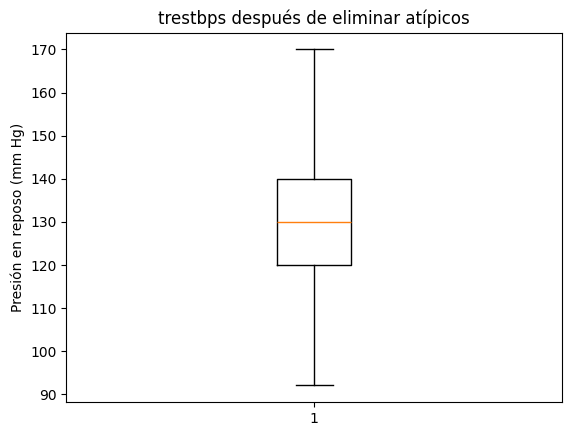

Filas eliminadas: 27
Pacientes restantes: 891
Columnas restantes: 12
Valores faltantes: 0


In [163]:
# Conservamos las filas que no se marcaron como atípicas.
cardio_df = cardio_df.loc[~es_atipico_trestbps]

plt.boxplot(cardio_df["trestbps"])
plt.title("trestbps después de eliminar atípicos")
plt.ylabel("Presión en reposo (mm Hg)")
plt.show()

print("Filas eliminadas:", es_atipico_trestbps.sum())
print("Pacientes restantes:", len(cardio_df))
print("Columnas restantes:", cardio_df.shape[1])
print("Valores faltantes:", cardio_df.isna().sum().sum())

Conclusión: Se eliminan 27 filas y quedan 891 pacientes, 12 columnas y cero faltantes. Se eliminan únicamente las filas señaladas por el IQR de trestbps calculado en la pregunta 9. No se eliminan atípicos de las otras variables. El boxplot final recalcula los cuartiles sobre la distribución depurada; no se aplica una eliminación iterativa. Esta eliminación se realiza para cumplir el ejercicio y no implica que todos los valores extremos sean errores de medición.

---

**Declaración de uso de IA**

OpenAI. (2026). Codex, basado en GPT-6 [Modelo de lenguaje grande], utilizado para generar y depurar código, revisar resultados y consultar de fuentes. https://openai.com/codex/

---